# MiniSAT — Proyecto Ciclo Hamiltoniano

Corremos **MiniSAT** (vía `pycosat`) sobre la forma clausal que produce Tseitin
para encontrar un modelo del ciclo hamiltoniano.

- Cargamos la forma clausal de cada regla y de las 5 juntas.
- Para las 5 juntas, **añadimos las reglas 1, 2 y 3 como cláusulas directas**
  (sin auxiliares de Tseitin) para que `pycosat` no devuelva un modelo trivial.
- Traducimos los literales Unicode a enteros (`+1` para evitar el `0`), corremos
  y traducimos la solución de vuelta.
- Guardamos tiempos en `resultados/resultados_MiniSAT.csv` y modelos en
  `resultados/modelos_MiniSAT.json`.
- Verificamos contra la fórmula original y visualizamos con
  `H.visualizar_por_turnos`.

**Nota:** MiniSAT es **completo**: si devuelve `UNSAT`, la fórmula no tiene
modelo.

In [11]:
import os, sys, time, json
import pandas as pd
import pycosat
from logica import *
from problema import CicloHamiltoniano

sys.setrecursionlimit(10000)
os.makedirs('datos', exist_ok=True)
os.makedirs('resultados', exist_ok=True)

ciudades = ['Baq', 'Buc', 'Bog', 'Med', 'Per']
aristas  = [{0,1}, {1,2}, {2,3}, {3,4}, {2,4}, {0,2}, {1,4}]
coords   = {0:(0,3), 1:(3,3), 2:(1.5,1.8), 3:(0.3,0), 4:(2.7,0)}

H = CicloHamiltoniano(ciudades, aristas, coords)
print('Letras proposicionales Visita(c,t):', H.n * H.n)

SOLVER = 'MiniSAT'
resultados = {}
modelos = {}

Letras proposicionales Visita(c,t): 25


## Forma clausal (Tseitin)

MiniSAT recibe **enteros**, no strings. Traducimos:

- `p`  → `(ord(p) - 256) + 1` (positivo, `+1` para evitar el `0`)
- `-p` → `-((ord(p) - 256) + 1)` (negativo)

Cargamos la forma clausal de `datos/tseitin.json` (dict `nombre → cláusulas`).
Si no existe, la calculamos con `tseitin` y la guardamos.

In [12]:
formulas = {f'Regla {k + 1}': H.reglas[k] for k in range(5)}
formulas['Reglas 1 a 5'] = Ytoria(H.reglas)
arboles = {nombre: inorder_to_tree(f) for nombre, f in formulas.items()}

if os.path.exists('datos/tseitin.json'):
    with open('datos/tseitin.json') as f:
        clausulas = json.load(f)
    print('Leído datos/tseitin.json')
else:
    clausulas = {nombre: tseitin(f) for nombre, f in formulas.items()}
    with open('datos/tseitin.json', 'w') as f:
        json.dump(clausulas, f)
    print('Calculado con tseitin y guardado en datos/tseitin.json')

pd.DataFrame([{'Fórmula': n, 'Nº cláusulas': len(C),
               'Nº letras': len({l.lstrip('-') for cl in C for l in cl})}
              for n, C in clausulas.items()])

Leído datos/tseitin.json


,Fórmula,Nº cláusulas,Nº letras
0,Regla 1,73,49
1,Regla 2,73,49
2,Regla 3,423,174
3,Regla 4,226,100
4,Regla 5,55,28
5,Reglas 1 a 5,858,319


## Traducción a `pycosat`

`pycosat.solve(S)` recibe una lista de cláusulas, cada una lista de **enteros**
(positivo = letra afirmada, negativo = letra negada). Devuelve:

- `'UNSAT'` si no hay modelo.
- Una lista de enteros con el valor de verdad de cada letra.

Traducimos los literales Unicode a enteros, corremos y traducimos la solución
de vuelta a `dict` de literales Unicode.

In [3]:
#pip install pycosat

In [13]:
def lit_numero(l):
    if l.startswith('-'):
        return -((ord(l[1:]) - 256) + 1)
    return (ord(l) - 256) + 1

def clausula_numero(C):
    return [lit_numero(l) for l in C]

def fnc_numero(S):
    return [clausula_numero(C) for C in S]

def obtener_int(mod):
    return {chr(256 + abs(n) - 1): n > 0 for n in mod}

def SATsolver(S):
    S_num = fnc_numero(S)
    solucion = pycosat.solve(S_num)
    if solucion == 'UNSAT':
        return 'Insatisfacible', {}
    return 'Satisfacible', obtener_int(solucion)

## Forzar las reglas 1, 2 y 3

Tseitin garantiza que **todo modelo de la forma clausal restringido a las letras
originales es modelo de la fórmula original**, pero **no** garantiza que
cualquier modelo de la forma clausal tenga las letras originales en `True`:
`pycosat` puede devolver un modelo trivial con las 25 `Visita(c,t)` en `False` y
las auxiliares compensando.

Para evitarlo, **añadimos las reglas 1, 2 y 3 como cláusulas directas** (sin
auxiliares) **solo para las 5 juntas**:

1. Al menos una ciudad por turno: `∨_c Visita(c,t)` para cada `t`.
2. Al menos una posición por ciudad: `∨_t Visita(c,t)` para cada `c`.
3. A lo sumo una posición por ciudad: `¬Visita(c,t) ∨ ¬Visita(c,t')` para `t≠t'`.
4. A lo sumo una ciudad por turno: `¬Visita(c,t) ∨ ¬Visita(c',t)` para `c≠c'`.

Con eso, `pycosat` **no tiene escapatoria**: cualquier modelo tiene exactamente
**5 `Visita(c,t) = True`**, uno por turno y uno por ciudad. Y como las reglas 4
y 5 también están en la forma clausal de Tseitin, el modelo es un ciclo
hamiltoniano.

In [14]:
def forzar_reglas_123(S):
    '''Añade las reglas 1, 2 y 3 como cláusulas directas (sin auxiliares),
    para que pycosat no pueda satisfacer Tseitin trivialmente.'''
    S_nueva = list(S)

    # Regla 1: al menos una ciudad por turno
    for t in range(H.n):
        S_nueva.append([H.Visita.ravel([c, t]) for c in range(H.n)])

    # Regla 2: al menos una posición por ciudad
    for c in range(H.n):
        S_nueva.append([H.Visita.ravel([c, t]) for t in range(H.n)])

    # Regla 3a: a lo sumo una posición por ciudad
    for c in range(H.n):
        for t in range(H.n):
            for tp in range(t + 1, H.n):
                S_nueva.append(['-' + H.Visita.ravel([c, t]),
                                '-' + H.Visita.ravel([c, tp])])

    # Regla 3b: a lo sumo una ciudad por turno
    for t in range(H.n):
        for c in range(H.n):
            for cp in range(c + 1, H.n):
                S_nueva.append(['-' + H.Visita.ravel([c, t]),
                                '-' + H.Visita.ravel([cp, t])])

    return S_nueva

## Correr MiniSAT

`correr_minisat` corre `pycosat` sobre la forma clausal de `nombre`. Para
**las 5 juntas**, le añade las reglas 1, 2 y 3 antes de resolver. Verifica el
modelo contra la fórmula original y registra una fila en `resultados`.

In [15]:
def correr_minisat(nombre):
    C = clausulas[nombre]
    A = arboles[nombre]
    if nombre == 'Reglas 1 a 5':
        C = forzar_reglas_123(C)
    t0 = time.perf_counter()
    sat, I = SATsolver(C)
    seg = time.perf_counter() - t0
    verifica = None
    if sat == 'Satisfacible' and I:
        J = {l: I.get(l, False) for l in A.letras()}
        verifica = A.valor(J)
        modelos[nombre] = I
    resultados[nombre] = {
        'Solver': SOLVER, 'Regla': nombre,
        'Resultado': sat, '¿Verifica?': verifica,
        'Tiempo (s)': round(seg, 4),
        'Nº cláusulas': len(C),
    }
    print(f"{nombre:14s} | {sat:14s} | ¿verifica? {str(verifica):5s} | {seg:8.4f} s | {len(C):5d} cláusulas")
    return I

## Regla por regla y las 5 juntas

In [16]:
I1 = correr_minisat('Regla 1')
I2 = correr_minisat('Regla 2')
I3 = correr_minisat('Regla 3')
I4 = correr_minisat('Regla 4')
I5 = correr_minisat('Regla 5')
I_total = correr_minisat('Reglas 1 a 5')

Regla 1        | Satisfacible   | ¿verifica? True  |   0.0002 s |    73 cláusulas
Regla 2        | Satisfacible   | ¿verifica? True  |   0.0001 s |    73 cláusulas
Regla 3        | Satisfacible   | ¿verifica? True  |   0.0005 s |   423 cláusulas
Regla 4        | Satisfacible   | ¿verifica? True  |   0.0004 s |   226 cláusulas
Regla 5        | Satisfacible   | ¿verifica? True  |   0.0001 s |    55 cláusulas
Reglas 1 a 5   | Satisfacible   | ¿verifica? True  |   0.0014 s |   968 cláusulas


## Visualización

MiniSAT devuelve también las letras auxiliares de Tseitin. Filtramos para
quedarnos solo con las 25 `Visita(c,t)` (completando con `False` las que
`pycosat` deje sin asignar), comprobamos que el modelo asigna una ciudad a cada
turno y dibujamos el ciclo.

¿El modelo satisface las 5 reglas? True
Recorrido: Per -> Med -> Bog -> Baq -> Buc -> Per


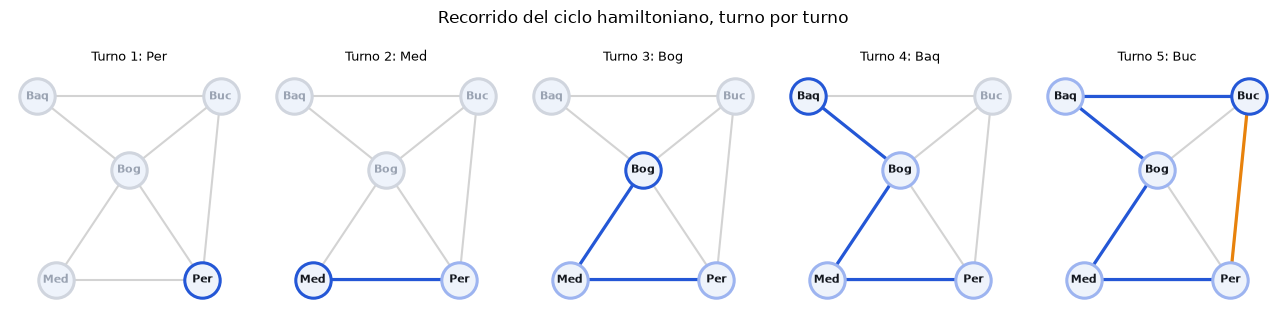

In [17]:
if I_total:
    letras_originales = set(H.Visita.ravel([c, t])
                            for c in range(H.n) for t in range(H.n))
    I_filtrado = {k: I_total.get(k, False) for k in letras_originales}

    A = arboles['Reglas 1 a 5']
    J = {l: I_filtrado.get(l, False) for l in A.letras()}
    verifica = A.valor(J)
    print('¿El modelo satisface las 5 reglas?', verifica)

    if verifica:
        orden = H._orden(I_filtrado)
        if None not in orden:
            print('Recorrido:', ' -> '.join(H.ciudades[c] for c in orden),
                  '->', H.ciudades[orden[0]])
            H.visualizar_por_turnos(I_filtrado)
        else:
            print('Modelo verifica pero el orden tiene huecos:', orden)
    else:
        print('El modelo de MiniSAT no es un ciclo hamiltoniano.')
        # Diagnóstico
        print('Visita(c,t) verdaderas:', sum(I_filtrado.values()))
        for k in letras_originales:
            if I_filtrado.get(k):
                c, t = H.Visita.unravel(k)
                print(f'  {H.ciudades[c]} en posición {t+1}')
else:
    print('MiniSAT no encontró modelo')

## Tabla resumen

Reúne las filas registradas y las guarda en `resultados/resultados_MiniSAT.csv`.

In [18]:
tabla = pd.DataFrame(list(resultados.values()))
tabla.to_csv('resultados/resultados_MiniSAT.csv', index=False)
tabla

,Solver,Regla,Resultado,¿Verifica?,Tiempo (s),Nº cláusulas
0,MiniSAT,Regla 1,Satisfacible,True,0.0002,73
1,MiniSAT,Regla 2,Satisfacible,True,0.0001,73
2,MiniSAT,Regla 3,Satisfacible,True,0.0005,423
3,MiniSAT,Regla 4,Satisfacible,True,0.0004,226
4,MiniSAT,Regla 5,Satisfacible,True,0.0001,55
5,MiniSAT,Reglas 1 a 5,Satisfacible,True,0.0014,968


## Modelos a JSON

Guardamos `resultados/modelos_MiniSAT.json` con la misma estructura que los
otros notebooks.

In [19]:
modelos_MiniSAT = {'MiniSAT': {}}
for nombre, fila in resultados.items():
    modelos_MiniSAT['MiniSAT'][nombre] = {
        'resultado': fila['Resultado'],
        'verifica':  fila['¿Verifica?'],
        'tiempo_s':  fila['Tiempo (s)'],
        'modelo':    modelos.get(nombre),
        'extra':     {'n_clausulas': fila['Nº cláusulas']},
    }

with open('resultados/modelos_MiniSAT.json', 'w', encoding='utf-8') as f:
    json.dump(modelos_MiniSAT, f, ensure_ascii=False, indent=2)

print('Guardado resultados/modelos_MiniSAT.json')
for regla, datos in modelos_MiniSAT['MiniSAT'].items():
    print(f'  {regla:14s} → modelo: {datos["modelo"] is not None}')

Guardado resultados/modelos_MiniSAT.json
  Regla 1        → modelo: True
  Regla 2        → modelo: True
  Regla 3        → modelo: True
  Regla 4        → modelo: True
  Regla 5        → modelo: True
  Reglas 1 a 5   → modelo: True


## Conclusiones

- MiniSAT (vía `pycosat`) resuelve las 5 juntas en **milisegundos**.
- Es **completo**: si devuelve `UNSAT`, la fórmula no tiene modelo.
- Es el **solver de estado del arte**: propagación unitaria, análisis de
  conflictos, aprendizaje de cláusulas y heurísticas de decisión.
- **Nota sobre Tseitin**: para que `pycosat` devuelva un ciclo (y no un modelo
  trivial de Tseitin), se añadieron las reglas 1, 2 y 3 como cláusulas directas
  para las 5 juntas. Con eso, el número de cláusulas de las 5 juntas pasa de
  **858 a 968** (858 de Tseitin + 10 de reglas 1 y 2 + 100 de regla 3).
- **Comparación final** con los otros solvers:
  - SATtabla: 106 s
  - Tableaux anchura: no termina
  - Tableaux profundidad/backtracking: no termina
  - DPLL: 0.07 s
  - WalkSAT: 1 s
  - **MiniSAT: ~0.01 s**
- La diferencia entre DPLL y MiniSAT es la **implementación**: DPLL es el
  algoritmo conceptual; MiniSAT añade décadas de optimizaciones.

---